# Training Pipeline for Cirrhosis Survival Prediction

This notebook trains and compares multiple machine-learning classifiers for **survival status prediction** on the Mayo Clinic PBC cirrhosis dataset.

Target classes (encoded in preprocessed data):
- `0` = D (death)
- `1` = C (censored)
- `2` = CL (censored due to liver transplantation)

In [5]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    cohen_kappa_score,
 )

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)

In [6]:
DATA_PATH = "./data/preprocessed/2_cirrhosis_patient_survival_prediction_preprocessed_df.csv"
LABEL = "Status"

df = pd.read_csv(DATA_PATH)
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

X = df.drop(columns=[LABEL])
y = df[LABEL].astype(int)

# class mapping from dataset page
class_name_map = {0: "D (death)", 1: "C (censored)", 2: "CL (liver transplant censored)"}
print("Class distribution:")
display(y.value_counts().sort_index().rename(index=class_name_map))

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Edema_N,Edema_S,Edema_Y
0,400,2,1,21464,0,1,1,1,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,3,0,0,1
1,4500,0,1,20617,0,0,1,1,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,2,1,0,0
2,1012,2,1,25594,1,0,0,0,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,3,0,1,0
3,1925,2,1,19994,0,0,1,1,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,3,0,1,0
4,1504,1,0,13918,0,0,1,1,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,2,1,0,0


Shape: (418, 21)
Columns: ['N_Days', 'Status', 'Drug', 'Age', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage', 'Edema_N', 'Edema_S', 'Edema_Y']
Class distribution:


Status
D (death)                         232
C (censored)                       25
CL (liver transplant censored)    161
Name: count, dtype: int64

In [7]:
import time

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Train/Test:", X_train.shape, X_test.shape)

def per_class_specificity_from_cm(cm):
    # One-vs-rest specificity for each class from multiclass confusion matrix
    total = cm.sum()
    specs = {}
    for i in range(cm.shape[0]):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - (tp + fn + fp)
        specs[i] = tn / (tn + fp) if (tn + fp) else np.nan
    return specs

def _final_estimator(model):
    # If model is a pipeline, return the final classifier step
    return model.steps[-1][1] if hasattr(model, "steps") else model

def _count_trainable_params(model):
    est = _final_estimator(model)

    if isinstance(est, LogisticRegression):
        return int(est.coef_.size + est.intercept_.size)

    if isinstance(est, SVC):
        return int(est.support_vectors_.size + est.dual_coef_.size + est.intercept_.size)

    if isinstance(est, KNeighborsClassifier):
        # KNN stores samples but does not learn trainable weights
        return 0

    if isinstance(est, DecisionTreeClassifier):
        return int(est.tree_.node_count)

    if isinstance(est, RandomForestClassifier):
        return int(sum(tree.tree_.node_count for tree in est.estimators_))

    if isinstance(est, GradientBoostingClassifier):
        return int(sum(tree.tree_.node_count for row in est.estimators_ for tree in row))

    if isinstance(est, MLPClassifier):
        return int(sum(w.size for w in est.coefs_) + sum(b.size for b in est.intercepts_))

    return np.nan

def evaluate_model(model, model_name, X_tr, y_tr, X_te, y_te):
    start = time.perf_counter()
    model.fit(X_tr, y_tr)
    training_time = time.perf_counter() - start

    y_pred_train = model.predict(X_tr)
    y_pred = model.predict(X_te)

    y_proba = model.predict_proba(X_te) if hasattr(model, "predict_proba") else None

    cm = confusion_matrix(y_te, y_pred, labels=sorted(y_te.unique()))
    class_recall = recall_score(y_te, y_pred, average=None, labels=sorted(y_te.unique()))
    class_precision = precision_score(y_te, y_pred, average=None, labels=sorted(y_te.unique()), zero_division=0)
    class_spec = per_class_specificity_from_cm(cm)

    train_acc = accuracy_score(y_tr, y_pred_train)
    test_acc = accuracy_score(y_te, y_pred)

    row = {
        "Model": model_name,
        "Training_Time_s": training_time,
        "Trainable_Params": _count_trainable_params(model),
        "Training_Accuracy": train_acc,
        "Test_Accuracy": test_acc,
        "Accuracy": test_acc,
        "Balanced_Accuracy": balanced_accuracy_score(y_te, y_pred),
        "F1_Macro": f1_score(y_te, y_pred, average="macro"),
        "F1_Weighted": f1_score(y_te, y_pred, average="weighted"),
        "Precision_Macro": precision_score(y_te, y_pred, average="macro", zero_division=0),
        "Recall_Macro": recall_score(y_te, y_pred, average="macro"),
        "MCC": matthews_corrcoef(y_te, y_pred),
        "Cohen_Kappa": cohen_kappa_score(y_te, y_pred),
    }

    if y_proba is not None:
        row["AUC_OvR_Macro"] = roc_auc_score(y_te, y_proba, multi_class="ovr", average="macro")
        row["AUC_OvR_Weighted"] = roc_auc_score(y_te, y_proba, multi_class="ovr", average="weighted")

    classes_sorted = sorted(y_te.unique())
    for idx, cls in enumerate(classes_sorted):
        row[f"Recall_Sensitivity_{cls}"] = class_recall[idx]
        row[f"Precision_PPV_{cls}"] = class_precision[idx]
        row[f"Specificity_{cls}"] = class_spec[cls]

    return row, y_pred, cm

Train/Test: (334, 20) (84, 20)


In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, random_state=SEED))
    ]),
    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=3.0, gamma="scale", probability=True, random_state=SEED))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=9))
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=6, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=SEED
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True, random_state=SEED))
    ]),
}

all_rows = []
best_model_name = None
best_score = -np.inf
best_cm = None
best_pred = None

for name, model in models.items():
    row, y_pred, cm = evaluate_model(model, name, X_train, y_train, X_test, y_test)
    all_rows.append(row)
    if row["F1_Macro"] > best_score:
        best_score = row["F1_Macro"]
        best_model_name = name
        best_cm = cm
        best_pred = y_pred

results_df = pd.DataFrame(all_rows).sort_values(["F1_Macro", "Test_Accuracy"], ascending=False).reset_index(drop=True)

# Keep these as raw values (no % scaling)
raw_cols = ["Training_Time_s", "Trainable_Params"]

# Scale all other metric columns to percentage
percent_cols = [c for c in results_df.columns if c not in ["Model", *raw_cols]]
results_display = results_df.copy()
results_display[percent_cols] = results_display[percent_cols] * 100

display(
    results_display.style.format({
        **{c: "{:.2f}" for c in percent_cols},
        "Training_Time_s": "{:.4f}",
        "Trainable_Params": "{:.0f}",
    })
)

# Focused table for requested training statistics
stats_cols = ["Model", "Training_Time_s", "Trainable_Params", "Training_Accuracy", "Test_Accuracy"]
display(
    results_display[stats_cols].style.format({
        "Training_Time_s": "{:.4f}",
        "Trainable_Params": "{:.0f}",
        "Training_Accuracy": "{:.2f}",
        "Test_Accuracy": "{:.2f}",
    })
)

print(f"Best model by macro-F1: {best_model_name} ({best_score:.4f})")

,Model,Training_Time_s,Trainable_Params,Training_Accuracy,Test_Accuracy,Accuracy,Balanced_Accuracy,F1_Macro,F1_Weighted,Precision_Macro,Recall_Macro,MCC,Cohen_Kappa,AUC_OvR_Macro,AUC_OvR_Weighted,Recall_Sensitivity_0,Precision_PPV_0,Specificity_0,Recall_Sensitivity_1,Precision_PPV_1,Specificity_1,Recall_Sensitivity_2,Precision_PPV_2,Specificity_2
0,Random Forest,0.3786,41136,99.70,75.00,75.00,52.33,51.27,73.03,50.37,52.33,51.59,51.20,68.56,80.26,85.11,76.92,67.57,0.00,0.00,98.73,71.88,74.19,84.62
1,Logistic Regression,0.0087,63,77.84,73.81,73.81,51.29,50.32,71.80,49.60,51.29,49.15,48.67,80.14,83.19,85.11,75.47,64.86,0.00,0.00,98.73,68.75,73.33,84.62
2,Gradient Boosting,0.2994,4224,100.00,70.24,70.24,48.49,47.96,68.61,47.88,48.49,42.38,41.86,70.18,80.74,82.98,72.22,59.46,0.00,0.00,97.47,62.50,71.43,84.62
3,SVM (RBF),0.0196,4931,90.72,70.24,70.24,48.83,47.91,68.33,47.23,48.83,42.08,41.67,72.60,77.24,80.85,71.70,59.46,0.00,0.00,98.73,65.62,70.00,82.69
4,MLP,0.0252,3523,76.35,70.24,70.24,49.16,47.65,68.08,46.24,49.16,42.24,41.96,67.27,76.12,78.72,74.00,64.86,0.00,0.00,100.00,68.75,64.71,76.92
5,KNN,0.0018,0,76.35,70.24,70.24,48.16,47.24,67.59,47.35,48.16,41.31,39.97,68.04,75.19,85.11,68.97,51.35,0.00,0.00,100.00,59.38,73.08,86.54
6,Decision Tree,0.0025,51,85.93,64.29,64.29,43.95,45.27,64.95,47.91,43.95,34.06,33.49,67.25,74.61,78.72,69.81,56.76,0.00,0.00,89.87,53.12,73.91,88.46


,Model,Training_Time_s,Trainable_Params,Training_Accuracy,Test_Accuracy
0,Random Forest,0.3786,41136,99.70,75.00
1,Logistic Regression,0.0087,63,77.84,73.81
2,Gradient Boosting,0.2994,4224,100.00,70.24
3,SVM (RBF),0.0196,4931,90.72,70.24
4,MLP,0.0252,3523,76.35,70.24
5,KNN,0.0018,0,76.35,70.24
6,Decision Tree,0.0025,51,85.93,64.29


Best model by macro-F1: Random Forest (0.5127)


Detailed classification report (best model):
                                precision    recall  f1-score   support

                     D (death)     0.7692    0.8511    0.8081        47
                  C (censored)     0.0000    0.0000    0.0000         5
CL (liver transplant censored)     0.7419    0.7188    0.7302        32

                      accuracy                         0.7500        84
                     macro avg     0.5037    0.5233    0.5127        84
                  weighted avg     0.7130    0.7500    0.7303        84



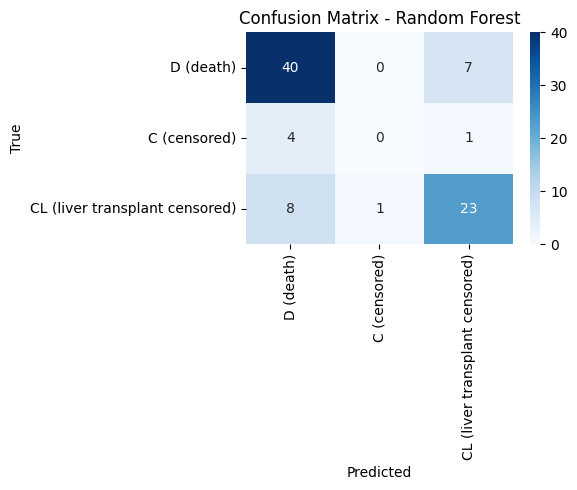

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

best_model = models[best_model_name]
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

print("Detailed classification report (best model):")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=[class_name_map[c] for c in sorted(y.unique())],
    digits=4
))

plt.figure(figsize=(6, 5))
sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[class_name_map[c] for c in sorted(y.unique())],
    yticklabels=[class_name_map[c] for c in sorted(y.unique())]
 )
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()